Number of pedestrians detected: 5


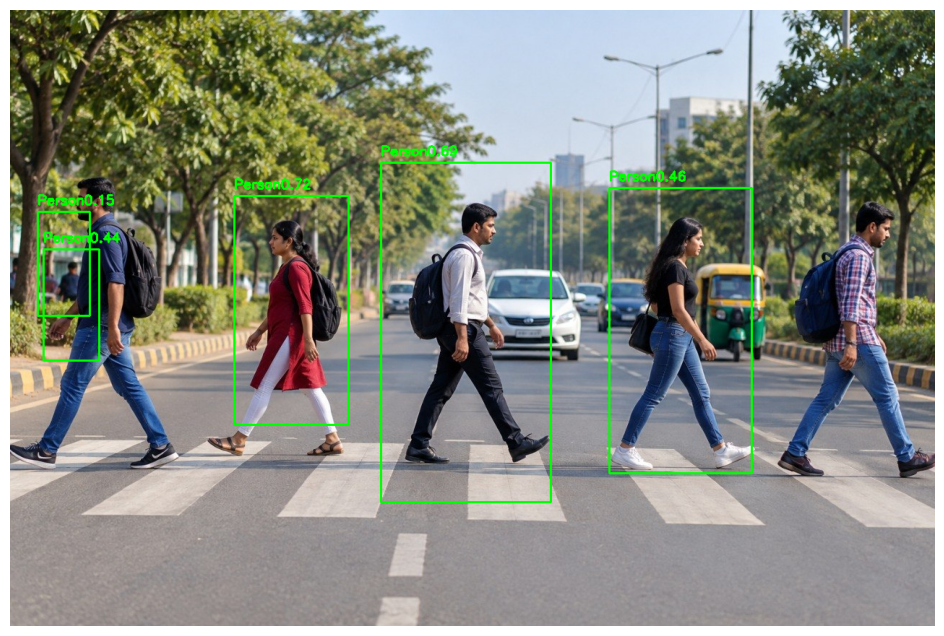

In [1]:
import sys, subprocess
try:
    import cv2
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "opencv-python-headless"])
    import cv2

image = cv2.imread("road1.jpg")
if image is None:
    print("Image not found!")
    exit()
hog = cv2.HOGDescriptor()
hog.setSVMDetector(
    cv2.HOGDescriptor_getDefaultPeopleDetector()
    )
rects, weights = hog.detectMultiScale (
    image,
    winStride = (4, 4),
    padding = (8, 8),
    scale = 1.03
)
for (x, y, w, h), weight in zip(rects, weights):
    cv2.rectangle(
        image, 
        (x, y),
        (x+w, y+h),
        (0, 255, 0),
        2
    )
    cv2.putText (
        image, 
        f"Person{float(weight):.2f}",
        (x, y - 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
)
print("Number of pedestrians detected:", len(rects))
import matplotlib.pyplot as plt
plt.figure(figsize=(12,8))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [2]:
from IPython.display import display
from ipywidgets import FileUpload

upload = FileUpload(accept='.jpg,.jpeg,.png', multiple=False)
display(upload)

FileUpload(value=(), accept='.jpg,.jpeg,.png', description='Upload')

In [3]:
if len(upload.value) > 0:
    uploaded_file = upload.value[0]
    filename = uploaded_file["name"]

    with open(filename, "wb") as f:
        f.write(uploaded_file["content"])

    print("Uploaded:", filename)
else:
    print("No file uploaded.")

No file uploaded.
